PATIENT READMISSION PREDICTION

Machine Learning Based Patient Readmission Analysis

Project Implementation

Objective:

To develop a machine learning-based system that predicts whether a patient will be readmitted to the hospital based on medical and hospital-related information.

In [4]:
print("Patient Readmission Prediction Project Started!")

Patient Readmission Prediction Project Started!


1. Introduction

Patient readmission refers to a situation where a patient returns to the hospital for treatment after being discharged.

Early readmission can increase healthcare costs and create additional challenges for hospitals and patients.

This project uses machine learning techniques to analyse patient and hospital-related information and predict the possibility of hospital readmission.

Project Objectives

- Analyse the hospital patient dataset.
- Apply data preprocessing techniques.
- Train different machine learning models.
- Compare model performance.
- Identify patients who may be readmitted within 30 days.

2. Dataset Description

The dataset used in this project is the Diabetes 130-US Hospitals dataset.

It contains hospital records of patients with diabetes, including demographic details, medical information, laboratory results and hospital admission details.

The dataset is used to analyse patient readmission patterns and develop machine learning models for predicting readmission.

Target Variable:
The readmitted column represents the patient’s readmission status:

* NO – No readmission
* 30 – Readmitted after 30 days
* <30 – Readmitted within 30 days

3. Environment Setup

The project uses Python and several machine learning and data analysis libraries.

The following libraries are used:

* Pandas: For dataset handling and manipulation.
* NumPy: For numerical operations.
* Matplotlib: For data visualisation.
* Seaborn: For statistical visualisation.
* Scikit-learn: For machine learning model development and evaluation.

In [5]:
%pip install pandas numpy matplotlib seaborn scikit-learn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


3.1 Importing Required Libraries

The required Python libraries are imported to perform data manipulation, numerical computations, data visualisation and machine learning operations.

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print("All libraries installed successfully!")

All libraries installed successfully!


3.2 Loading the Dataset

The dataset is loaded into a Pandas DataFrame using the read_csv() function.

This allows us to access, analyse and process the patient records for further machine learning operations.

In [7]:
import pandas as pd

df = pd.read_csv("Dataset/diabetic_data.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


3.3 Dataset Dimensions

The dataset contains 101,766 patient records and 50 columns.

* Rows represent individual patient encounters.
* Columns represent patient demographics, medical information, hospital details and readmission status.

This confirms that the dataset contains a substantial amount of information for further analysis and machine learning.

In [8]:
print("Dataset Shape:", df.shape)

Dataset Shape: (101766, 50)


3.4 Understanding Dataset Features

The dataset contains 50 columns representing different patient and hospital-related attributes.

These features include:

* Patient demographic information.
* Admission and discharge details.
* Medical conditions and diagnoses.
* Laboratory and medication information.
* Hospital readmission status.

The column names help us understand the information available for further analysis and model development.

In [9]:
print(df.columns.tolist())

['encounter_id', 'patient_nbr', 'race', 'gender', 'age', 'weight', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'time_in_hospital', 'payer_code', 'medical_specialty', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'diag_1', 'diag_2', 'diag_3', 'number_diagnoses', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted']


3.5 Preview of the Dataset

The head() function displays the first five records of the dataset.

This helps us examine the patient information, understand the dataset structure and identify the features available for analysis.

In [10]:
df.head()

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


3.4 Dataset Information

The info() function provides a summary of the dataset, including column names, number of non-null values, data types and memory usage. It helps us understand the structure and completeness of the dataset.

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype 
---  ------                    --------------   ----- 
 0   encounter_id              101766 non-null  int64 
 1   patient_nbr               101766 non-null  int64 
 2   race                      101766 non-null  object
 3   gender                    101766 non-null  object
 4   age                       101766 non-null  object
 5   weight                    101766 non-null  object
 6   admission_type_id         101766 non-null  int64 
 7   discharge_disposition_id  101766 non-null  int64 
 8   admission_source_id       101766 non-null  int64 
 9   time_in_hospital          101766 non-null  int64 
 10  payer_code                101766 non-null  object
 11  medical_specialty         101766 non-null  object
 12  num_lab_procedures        101766 non-null  int64 
 13  num_procedures            101766 non-null  int64 
 14  num_

3.5 Checking Missing Values

The isnull().sum() function is used to identify and count missing values in each column of the dataset. This helps us understand incomplete data and determine whether data cleaning is required before model training.

In [12]:
df.isnull().sum()

encounter_id                    0
patient_nbr                     0
race                            0
gender                          0
age                             0
weight                          0
admission_type_id               0
discharge_disposition_id        0
admission_source_id             0
time_in_hospital                0
payer_code                      0
medical_specialty               0
num_lab_procedures              0
num_procedures                  0
num_medications                 0
number_outpatient               0
number_emergency                0
number_inpatient                0
diag_1                          0
diag_2                          0
diag_3                          0
number_diagnoses                0
max_glu_serum               96420
A1Cresult                   84748
metformin                       0
repaglinide                     0
nateglinide                     0
chlorpropamide                  0
glimepiride                     0
acetohexamide 

3.6 Checking Missing Values Represented by Question Marks

In the dataset, some missing values are represented by the symbol ‘?’, instead of standard null values.

The following analysis identifies and counts the question mark values present in each column.

This step helps detect additional missing data that must be handled during preprocessing.

In [13]:
(df == '?').sum()

encounter_id                    0
patient_nbr                     0
race                         2273
gender                          0
age                             0
weight                      98569
admission_type_id               0
discharge_disposition_id        0
admission_source_id             0
time_in_hospital                0
payer_code                  40256
medical_specialty           49949
num_lab_procedures              0
num_procedures                  0
num_medications                 0
number_outpatient               0
number_emergency                0
number_inpatient                0
diag_1                         21
diag_2                        358
diag_3                       1423
number_diagnoses                0
max_glu_serum                   0
A1Cresult                       0
metformin                       0
repaglinide                     0
nateglinide                     0
chlorpropamide                  0
glimepiride                     0
acetohexamide 

Calculating the Percentage of Missing Values
The following analysis calculates the percentage of missing values in each column and identifies columns with incomplete data.

In [14]:
missing_percent = (df.isnull().sum() / len(df)) * 100
print(missing_percent[missing_percent > 0].sort_values(ascending=False))

max_glu_serum    94.746772
A1Cresult        83.277322
dtype: float64


Checking the Distribution of Readmission Status

The readmitted column represents the hospital readmission status of patients.
The following analysis counts the number of patients readmitted within 30 days, after 30 days, and those who were not readmitted.
This helps understand the distribution of patient readmission categories in the dataset.

In [15]:
print(df['readmitted'].value_counts())

readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64


Duplicate Record Analysis

Duplicate records are identified to assess the quality and consistency of the dataset. The `duplicated()` function detects repeated rows, while `sum()` calculates the total number of duplicate records present in the dataset.

In [16]:
print("Duplicate records:", df.duplicated().sum())

Duplicate records: 0


 Dataset Data Types

The data types of all columns are examined to identify numerical and categorical features and determine suitable preprocessing techniques.

In [17]:
df.dtypes

encounter_id                 int64
patient_nbr                  int64
race                        object
gender                      object
age                         object
weight                      object
admission_type_id            int64
discharge_disposition_id     int64
admission_source_id          int64
time_in_hospital             int64
payer_code                  object
medical_specialty           object
num_lab_procedures           int64
num_procedures               int64
num_medications              int64
number_outpatient            int64
number_emergency             int64
number_inpatient             int64
diag_1                      object
diag_2                      object
diag_3                      object
number_diagnoses             int64
max_glu_serum               object
A1Cresult                   object
metformin                   object
repaglinide                 object
nateglinide                 object
chlorpropamide              object
glimepiride         

Target Variable Encoding

The categorical values of the target variable `readmitted` are converted into numerical labels (0, 1 and 2) to make them suitable for machine learning algorithms.

In [18]:
df['readmitted'] = df['readmitted'].map({
    'NO': 0,
    '>30': 1,
    '<30': 2
})

print(df['readmitted'].value_counts())

readmitted
0    54864
1    35545
2    11357
Name: count, dtype: int64


 Encoded Class Distribution

Displays the number of records in each readmission category after numerical encoding.

In [19]:
print(df['readmitted'].value_counts())

readmitted
0    54864
1    35545
2    11357
Name: count, dtype: int64


Feature and Target Variable Separation

The input features (X) and target variable (y) are separated. Unnecessary ID columns are removed from the input features, and the shapes of both datasets are displayed.

In [20]:
X = df.drop(columns=['encounter_id', 'patient_nbr', 'readmitted'])

y = df['readmitted']

print("Input features shape:", X.shape)
print("Target shape:", y.shape)

Input features shape: (101766, 47)
Target shape: (101766,)


 Identification of Categorical Features

Categorical columns are identified from the input dataset for further preprocessing.

In [21]:
cat_cols = X.select_dtypes(include=['object']).columns

print("Number of categorical columns:", len(cat_cols))
print(cat_cols.tolist())

Number of categorical columns: 36
['race', 'gender', 'age', 'weight', 'payer_code', 'medical_specialty', 'diag_1', 'diag_2', 'diag_3', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed']


Unique Category Count

The number of unique values in each categorical column is calculated to understand the variety of categories present in the dataset.

In [22]:
for col in cat_cols:
    print(col, ":", X[col].nunique())

race : 6
gender : 3
age : 10
weight : 10
payer_code : 18
medical_specialty : 73
diag_1 : 717
diag_2 : 749
diag_3 : 790
max_glu_serum : 3
A1Cresult : 3
metformin : 4
repaglinide : 4
nateglinide : 4
chlorpropamide : 4
glimepiride : 4
acetohexamide : 2
glipizide : 4
glyburide : 4
tolbutamide : 2
pioglitazone : 4
rosiglitazone : 4
acarbose : 4
miglitol : 4
troglitazone : 2
tolazamide : 3
examide : 1
citoglipton : 1
insulin : 4
glyburide-metformin : 4
glipizide-metformin : 2
glimepiride-pioglitazone : 2
metformin-rosiglitazone : 2
metformin-pioglitazone : 2
change : 2
diabetesMed : 2


Categorical Feature Analysis

Displays the number of unique categories in each categorical column, arranged in descending order.

In [23]:
print(X[cat_cols].nunique().sort_values(ascending=False))

diag_3                      790
diag_2                      749
diag_1                      717
medical_specialty            73
payer_code                   18
weight                       10
age                          10
race                          6
glyburide-metformin           4
metformin                     4
nateglinide                   4
repaglinide                   4
glipizide                     4
glyburide                     4
chlorpropamide                4
glimepiride                   4
miglitol                      4
acarbose                      4
rosiglitazone                 4
pioglitazone                  4
insulin                       4
gender                        3
max_glu_serum                 3
A1Cresult                     3
tolazamide                    3
acetohexamide                 2
tolbutamide                   2
troglitazone                  2
metformin-rosiglitazone       2
metformin-pioglitazone        2
glipizide-metformin           2
glimepir

 Missing Value Analysis

Identifies columns containing missing values and displays their counts.

In [24]:
missing = X.isnull().sum()
print(missing[missing > 0])

max_glu_serum    96420
A1Cresult        84748
dtype: int64


Handling Missing Values

Missing values in `max_glu_serum` and `A1Cresult` are replaced with "Not measured".

In [25]:
X[['max_glu_serum', 'A1Cresult']] = X[['max_glu_serum', 'A1Cresult']].fillna('Not measured')

Missing Value Verification

Checks whether any missing values remain in the selected columns after replacement.

In [26]:
print(X[['max_glu_serum', 'A1Cresult']].isnull().sum())

max_glu_serum    0
A1Cresult        0
dtype: int64


Splitting the Dataset

The dataset is divided into 80% training data and 20% testing data. Training data is used to build the models, while testing data evaluates their performance. Stratified sampling maintains class distribution in both sets.

In [27]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (81412, 47)
Testing data: (20354, 47)


Diagnosis Feature Analysis

The number of unique values in the three diagnosis columns is checked to understand their category variations before preprocessing.

In [28]:
for col in ['diag_1', 'diag_2', 'diag_3']:
    print(col, X_train[col].nunique())

diag_1 701
diag_2 725
diag_3 759


Categorical Feature Encoding

One-Hot Encoding converts categorical features into numerical values. The ColumnTransformer applies encoding to categorical columns while keeping the remaining numerical features unchanged. The same transformation is applied to both training and testing data.

In [29]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

cat_cols = X_train.select_dtypes(include=['object']).columns

preprocessor = ColumnTransformer(
    transformers=[
        ('categorical', OneHotEncoder(handle_unknown='ignore'), cat_cols)
    ],
    remainder='passthrough'
)

X_train_encoded = preprocessor.fit_transform(X_train)
X_test_encoded = preprocessor.transform(X_test)

print("Training data after encoding:", X_train_encoded.shape)
print("Testing data after encoding:", X_test_encoded.shape)

Training data after encoding: (81412, 2396)
Testing data after encoding: (20354, 2396)


Random Forest Model Training

A Random Forest classifier is created and trained using the encoded training data. It uses multiple decision trees to make predictions and applies balanced class weights to handle class imbalance.

In [30]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1,
    class_weight='balanced'
)

model.fit(X_train_encoded, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


 Random Forest Model Evaluation

The trained model predicts readmission categories using testing data. Its performance is evaluated using accuracy, precision, recall, F1-score and a confusion matrix.

In [31]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

y_pred = model.predict(X_test_encoded)

print("Model Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Model Accuracy: 0.5800825390586617

Classification Report:
              precision    recall  f1-score   support

           0       0.60      0.88      0.71     10973
           1       0.51      0.30      0.38      7109
           2       0.33      0.01      0.01      2272

    accuracy                           0.58     20354
   macro avg       0.48      0.40      0.37     20354
weighted avg       0.54      0.58      0.52     20354


Confusion Matrix:
[[9666 1300    7]
 [4959 2126   24]
 [1525  732   15]]


Improved Random Forest Model

The Random Forest model is retrained using custom class weights to give more importance to class 2 and improve its prediction performance.

In [32]:
model2 = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1,
    class_weight={0: 1, 1: 1, 2: 4}
)

model2.fit(X_train_encoded, y_train)

print("Improved Random Forest model trained!")

Improved Random Forest model trained!


Improved Random Forest Model Evaluation

The improved model is used to predict patient readmission. Its performance is measured using accuracy, precision, recall, F1-score and a confusion matrix.

In [33]:
y_pred2 = model2.predict(X_test_encoded)

print("Improved Model Accuracy:", accuracy_score(y_test, y_pred2))

print("\nClassification Report:")
print(classification_report(y_test, y_pred2))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred2))

Improved Model Accuracy: 0.5804264518030854

Classification Report:
              precision    recall  f1-score   support

           0       0.60      0.89      0.71     10973
           1       0.51      0.29      0.37      7109
           2       0.33      0.01      0.02      2272

    accuracy                           0.58     20354
   macro avg       0.48      0.39      0.37     20354
weighted avg       0.54      0.58      0.52     20354


Confusion Matrix:
[[9751 1214    8]
 [5035 2045   29]
 [1532  722   18]]


Installing Imbalanced-Learn Library

Installs the imbalanced-learn library, which provides SMOTE for handling class imbalance in the dataset.

In [34]:
%pip install imbalanced-learn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


Handling Class Imbalance Using SMOTE

SMOTE generates synthetic samples for minority classes to balance the training dataset. This helps the model learn from all readmission categories more effectively.

In [35]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)

X_train_balanced, y_train_balanced = smote.fit_resample(
    X_train_encoded, y_train
)

print("Before SMOTE:")
print(y_train.value_counts())

print("\nAfter SMOTE:")
print(y_train_balanced.value_counts())

Before SMOTE:
readmitted
0    43891
1    28436
2     9085
Name: count, dtype: int64

After SMOTE:
readmitted
0    43891
2    43891
1    43891
Name: count, dtype: int64


Random Forest Model with SMOTE

A Random Forest classifier is trained using the balanced dataset generated by SMOTE to improve learning across all readmission classes.

In [36]:
model3 = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

model3.fit(X_train_balanced, y_train_balanced)

print("SMOTE Random Forest model trained successfully!")

SMOTE Random Forest model trained successfully!


SMOTE Random Forest Model Evaluation

The trained model predicts readmission categories using testing data. Its performance is evaluated using accuracy, precision, recall, F1-score and a confusion matrix.

In [37]:
y_pred3 = model3.predict(X_test_encoded)

print("SMOTE Model Accuracy:", accuracy_score(y_test, y_pred3))

print("\nClassification Report:")
print(classification_report(y_test, y_pred3))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred3))

SMOTE Model Accuracy: 0.5809177557236906

Classification Report:
              precision    recall  f1-score   support

           0       0.60      0.87      0.71     10973
           1       0.51      0.32      0.39      7109
           2       0.37      0.01      0.03      2272

    accuracy                           0.58     20354
   macro avg       0.49      0.40      0.38     20354
weighted avg       0.54      0.58      0.52     20354


Confusion Matrix:
[[9518 1441   14]
 [4794 2274   41]
 [1476  764   32]]


 Model Performance Comparison

The performance of the three Random Forest models is compared using accuracy, precision, recall and F1-score to identify the better-performing model.

In [38]:
comparison = pd.DataFrame({
    'Model': ['Random Forest', 'Class Weight', 'SMOTE Random Forest'],
    'Accuracy': [0.5800, 0.5800, 0.58091],
    'Class 2 Precision': [0.33, 0.33, 0.37],
    'Class 2 Recall': [0.01, 0.01, 0.01],
    'Class 2 F1 Score': [0.01, 0.02, 0.03]
})

print(comparison)

                 Model  Accuracy  Class 2 Precision  Class 2 Recall  \
0        Random Forest   0.58000               0.33            0.01   
1         Class Weight   0.58000               0.33            0.01   
2  SMOTE Random Forest   0.58091               0.37            0.01   

   Class 2 F1 Score  
0              0.01  
1              0.02  
2              0.03  


Interpretation of Model Performance

The comparison results show that all three Random Forest models achieved nearly similar accuracy. However, the SMOTE Random Forest model performed slightly better in terms of Class 2 precision and F1-score. The recall values remain low across all models, indicating that further improvement is required to identify readmission cases effectively.

Dataset Dimensions

The dataset is loaded again to verify its original dimensions. It contains 101,766 records and 50 columns.

In [39]:
df = pd.read_csv("Dataset/diabetic_data.csv")
print(df.shape)

(101766, 50)


Target Variable Encoding

The readmitted column represents whether a patient was readmitted to the hospital. The categorical values are converted into numerical labels to make them suitable for machine learning model processing.

- NO → 0 (Not readmitted)
- «30 → 1 (Readmitted after 30 days)»
- <30 → 2 (Readmitted within 30 days)

The value counts are displayed to understand the distribution of the target classes.

In [40]:
df['readmitted'] = df['readmitted'].map({
    'NO': 0,
    '>30': 1,
    '<30': 2
})

print(df['readmitted'].value_counts())

readmitted
0    54864
1    35545
2    11357
Name: count, dtype: int64


Feature and Target Variable Separation

The dataset is divided into input features (X) and the target variable (y). Identifier columns are removed, and the "readmitted" column is used as the target for prediction.

In [41]:
X = df.drop(columns=['encounter_id', 'patient_nbr', 'readmitted'])
y = df['readmitted']

print(X.shape)
print(y.shape)

(101766, 47)
(101766,)


Splitting the Dataset

The dataset is divided into 80% training data and 20% testing data. Stratified sampling is used to maintain the same class distribution in both sets.

In [42]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(X_train.shape)
print(X_test.shape)

(81412, 47)
(20354, 47)


Identifying Feature Types

Categorical and numerical columns are identified separately to prepare the data for preprocessing and model training.

In [43]:
cat_cols = X_train.select_dtypes(include=['object']).columns

cat_indices = [X_train.columns.get_loc(col) for col in cat_cols]

print("Categorical columns:", len(cat_indices))
print("Numerical columns:", len(X_train.columns) - len(cat_indices))

Categorical columns: 36
Numerical columns: 11


Handling Missing Values

Missing values in the "max_glu_serum" and "A1Cresult" columns are replaced with 'Not measured' in both training and testing datasets.

In [44]:
X_train[['max_glu_serum', 'A1Cresult']] = X_train[['max_glu_serum', 'A1Cresult']].fillna('Not measured')

X_test[['max_glu_serum', 'A1Cresult']] = X_test[['max_glu_serum', 'A1Cresult']].fillna('Not measured')

print(X_train.isnull().sum().sum())
print(X_test.isnull().sum().sum())

0
0


Handling Class Imbalance using SMOTENC

SMOTENC is applied to balance the training dataset by generating synthetic samples for minority classes while considering categorical features.

In [45]:
from imblearn.over_sampling import SMOTENC

smotenc = SMOTENC(
    categorical_features=cat_indices,
    random_state=42
)

X_train_balanced2, y_train_balanced2 = smotenc.fit_resample(
    X_train, y_train
)

print(y_train_balanced2.value_counts())

readmitted
0    43891
2    43891
1    43891
Name: count, dtype: int64


Importing Pandas

Pandas is imported for data manipulation and analysis.

In [46]:
import pandas as pd

One-Hot Encoding of Categorical Features

The ColumnTransformer and OneHotEncoder are used to convert categorical features into numerical values. The preprocessor is fitted on the balanced training data and applied to the testing data to maintain consistent encoding.

In [47]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

preprocessor2 = ColumnTransformer(
    [('categorical', OneHotEncoder(handle_unknown='ignore'), cat_cols)],
    remainder='passthrough'
)

X_train_balanced_encoded = preprocessor2.fit_transform(X_train_balanced2)
X_test_encoded2 = preprocessor2.transform(X_test)

print(X_train_balanced_encoded.shape)
print(X_test_encoded2.shape)

(131673, 2396)
(20354, 2396)


Training SMOTENC Random Forest Model

A Random Forest classifier is trained using the balanced and encoded training dataset to predict patient readmission categories.

In [48]:
from sklearn.ensemble import RandomForestClassifier

model4 = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

model4.fit(X_train_balanced_encoded, y_train_balanced2)

print("SMOTENC Random Forest model trained successfully!")

SMOTENC Random Forest model trained successfully!


Evaluating SMOTENC Random Forest Model

The trained model is tested using unseen data. Accuracy, classification report, and confusion matrix are used to evaluate its prediction performance.

In [49]:
y_pred4 = model4.predict(X_test_encoded2)

print("SMOTENC Model Accuracy:", accuracy_score(y_test, y_pred4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred4))

SMOTENC Model Accuracy: 0.5443156136385968

Classification Report:
              precision    recall  f1-score   support

           0       0.63      0.72      0.67     10973
           1       0.47      0.40      0.43      7109
           2       0.20      0.15      0.17      2272

    accuracy                           0.54     20354
   macro avg       0.43      0.42      0.43     20354
weighted avg       0.53      0.54      0.53     20354


Confusion Matrix:
[[7876 2370  727]
 [3554 2855  700]
 [1047  877  348]]


Importing Logistic Regression

Logistic Regression is imported from Scikit-learn to build a classification model for predicting patient readmission.

In [50]:
from sklearn.linear_model import LogisticRegression

Training Logistic Regression Model

A Logistic Regression classifier is trained using the balanced and encoded training dataset to predict patient readmission categories.

In [51]:
model5 = LogisticRegression(
    max_iter=200,
    solver='lbfgs',
    random_state=42
)

model5.fit(X_train_balanced_encoded, y_train_balanced2)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


C:\Users\Neelamma\AppData\Roaming\Python\Python313\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 200 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=200).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Evaluating Logistic Regression Model

The Logistic Regression model is evaluated using the testing dataset. Accuracy, classification report, and confusion matrix are used to measure its prediction performance.

In [52]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

y_pred5 = model5.predict(X_test_encoded2)

print("Logistic Regression Accuracy:", accuracy_score(y_test, y_pred5))

print("\nClassification Report:")
print(classification_report(y_test, y_pred5))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred5))

Logistic Regression Accuracy: 0.5040778225410238

Classification Report:
              precision    recall  f1-score   support

           0       0.64      0.64      0.64     10973
           1       0.46      0.37      0.41      7109
           2       0.17      0.27      0.21      2272

    accuracy                           0.50     20354
   macro avg       0.42      0.43      0.42     20354
weighted avg       0.52      0.50      0.51     20354


Confusion Matrix:
[[6990 2350 1633]
 [3103 2662 1344]
 [ 907  757  608]]


Comparison of Machine Learning Models

The performance of five machine learning models is compared using accuracy, Class 2 recall, and F1-score to identify the better-performing model.

In [53]:
comparison = pd.DataFrame({
    'Model': [
        'Random Forest',
        'RF with Class Weights',
        'RF with SMOTE',
        'RF with SMOTENC',
        'Logistic Regression'
    ],
    'Accuracy': [0.5800, 0.5800, 0.58091, 0.5443, 0.5041],
    'Class 2 Recall': [0.01, 0.01, 0.01, 0.15, 0.27],
    'Class 2 F1 Score': [0.01, 0.02, 0.03, 0.17, 0.21]
})

print(comparison)

                   Model  Accuracy  Class 2 Recall  Class 2 F1 Score
0          Random Forest   0.58000            0.01              0.01
1  RF with Class Weights   0.58000            0.01              0.02
2          RF with SMOTE   0.58091            0.01              0.03
3        RF with SMOTENC   0.54430            0.15              0.17
4    Logistic Regression   0.50410            0.27              0.21


Importing StandardScaler

StandardScaler is imported from Scikit-learn to standardize numerical features by bringing them to a common scale.

In [54]:
from sklearn.preprocessing import StandardScaler

Feature Scaling using StandardScaler

StandardScaler is applied to standardize the encoded features. The scaler is fitted on the training data and then applied to the testing data to maintain consistency.

In [55]:
scaler = StandardScaler(with_mean=False)

X_train_scaled = scaler.fit_transform(X_train_balanced_encoded)
X_test_scaled = scaler.transform(X_test_encoded2)

print(X_train_scaled.shape)
print(X_test_scaled.shape)

(131673, 2396)
(20354, 2396)


Training Scaled Logistic Regression Model

A Logistic Regression classifier is trained using the scaled and balanced training dataset to improve model convergence and predict patient readmission categories.

In [56]:
model6 = LogisticRegression(
    max_iter=1000,
    random_state=42
)

model6.fit(X_train_scaled, y_train_balanced2)

print("Scaled Logistic Regression model trained successfully!")

Scaled Logistic Regression model trained successfully!


C:\Users\Neelamma\AppData\Roaming\Python\Python313\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Evaluating Scaled Logistic Regression Model

The scaled Logistic Regression model is evaluated using the testing dataset. Accuracy, classification report, and confusion matrix are used to measure its performance.

In [57]:
y_pred6 = model6.predict(X_test_scaled)

print("Scaled Logistic Regression Accuracy:",
      accuracy_score(y_test, y_pred6))

print("\nClassification Report:")
print(classification_report(y_test, y_pred6))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred6))

Scaled Logistic Regression Accuracy: 0.49926304411909206

Classification Report:
              precision    recall  f1-score   support

           0       0.64      0.60      0.62     10973
           1       0.45      0.42      0.44      7109
           2       0.17      0.25      0.21      2272

    accuracy                           0.50     20354
   macro avg       0.42      0.42      0.42     20354
weighted avg       0.52      0.50      0.51     20354


Confusion Matrix:
[[6585 2868 1520]
 [2915 3008 1186]
 [ 864  839  569]]


Training Tuned Random Forest Model

A tuned Random Forest classifier is trained using adjusted hyperparameters and class weights to improve prediction performance on patient readmission data.

In [58]:
model7 = RandomForestClassifier(
    n_estimators=100,
    max_depth=20,
    min_samples_split=10,
    min_samples_leaf=4,
    random_state=42,
    n_jobs=-1,
    class_weight='balanced'
)

model7.fit(X_train_balanced_encoded, y_train_balanced2)

print("Tuned Random Forest model trained successfully!")

Tuned Random Forest model trained successfully!


Evaluating Tuned Random Forest Model

The tuned Random Forest model is evaluated on the testing dataset using accuracy, classification report, and confusion matrix to assess its prediction performance.

In [59]:
y_pred7 = model7.predict(X_test_encoded2)

print("Tuned Random Forest Accuracy:",
      accuracy_score(y_test, y_pred7))

print("\nClassification Report:")
print(classification_report(y_test, y_pred7))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred7))

Tuned Random Forest Accuracy: 0.49832956666994205

Classification Report:
              precision    recall  f1-score   support

           0       0.62      0.69      0.65     10973
           1       0.49      0.27      0.35      7109
           2       0.15      0.28      0.20      2272

    accuracy                           0.50     20354
   macro avg       0.42      0.41      0.40     20354
weighted avg       0.52      0.50      0.50     20354


Confusion Matrix:
[[7579 1388 2006]
 [3572 1923 1614]
 [1040  591  641]]


Comparison of Machine Learning Models

The performance of seven trained models is compared using accuracy, Class 2 recall, and Class 2 F1-score to identify the most suitable model for patient readmission prediction.

In [60]:
comparison = pd.DataFrame({
    'Model': [
        'Random Forest',
        'RF with Class Weights',
        'RF with SMOTE',
        'RF with SMOTENC',
        'Logistic Regression',
        'Scaled Logistic Regression',
        'Tuned Random Forest'
    ],
    'Accuracy': [
        0.5800, 0.5800, 0.58091, 0.5443,
        0.5041, 0.4993, 0.4983
    ],
    'Class 2 Recall': [
        0.01, 0.01, 0.01, 0.15, 0.27, 0.25, 0.28
    ],
    'Class 2 F1 Score': [
        0.01, 0.02, 0.03, 0.17, 0.21, 0.21, 0.20
    ]
})

print(comparison)

                        Model  Accuracy  Class 2 Recall  Class 2 F1 Score
0               Random Forest   0.58000            0.01              0.01
1       RF with Class Weights   0.58000            0.01              0.02
2               RF with SMOTE   0.58091            0.01              0.03
3             RF with SMOTENC   0.54430            0.15              0.17
4         Logistic Regression   0.50410            0.27              0.21
5  Scaled Logistic Regression   0.49930            0.25              0.21
6         Tuned Random Forest   0.49830            0.28              0.20


Training Logistic Regression Model

A Logistic Regression classifier is trained using the balanced and encoded training dataset to predict patient readmission categories.

In [61]:
model5 = LogisticRegression(
    max_iter=200,
    solver='lbfgs',
    random_state=42
)

model5.fit(X_train_balanced_encoded, y_train_balanced2)

C:\Users\Neelamma\AppData\Roaming\Python\Python313\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 200 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=200).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,42
,solver,'lbfgs'
,max_iter,200
,multi_class,'deprecated'


Evaluating Logistic Regression Model

The Logistic Regression model is evaluated using the testing dataset. Accuracy and classification report are used to assess its prediction performance.

In [62]:
y_pred5 = model5.predict(X_test_encoded2)

print("Accuracy:", accuracy_score(y_test, y_pred5))
print(classification_report(y_test, y_pred5))

Accuracy: 0.5040778225410238
              precision    recall  f1-score   support

           0       0.64      0.64      0.64     10973
           1       0.46      0.37      0.41      7109
           2       0.17      0.27      0.21      2272

    accuracy                           0.50     20354
   macro avg       0.42      0.43      0.42     20354
weighted avg       0.52      0.50      0.51     20354



Confusion Matrix of Logistic Regression Model

The confusion matrix is used to examine the correct and incorrect predictions made by the Logistic Regression model across the three readmission classes.

In [63]:
from sklearn.metrics import confusion_matrix
print(confusion_matrix(y_test, y_pred5))

[[6990 2350 1633]
 [3103 2662 1344]
 [ 907  757  608]]


Logistic Regression Model Parameters

Displays the hyperparameter settings used in the Logistic Regression model 

In [64]:
print(model5.get_params())

{'C': 1.0, 'class_weight': None, 'dual': False, 'fit_intercept': True, 'intercept_scaling': 1, 'l1_ratio': None, 'max_iter': 200, 'multi_class': 'deprecated', 'n_jobs': None, 'penalty': 'l2', 'random_state': 42, 'solver': 'lbfgs', 'tol': 0.0001, 'verbose': 0, 'warm_start': False}


Training Logistic Regression with Class Weights

A Logistic Regression model is trained using balanced class weights to improve the prediction of underrepresented readmission classes.

In [65]:
model6 = LogisticRegression(
    max_iter=200,
    solver='lbfgs',
    class_weight='balanced',
    random_state=42
)

model6.fit(X_train_balanced_encoded, y_train_balanced2)

C:\Users\Neelamma\AppData\Roaming\Python\Python313\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 200 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=200).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,'balanced'
,random_state,42
,solver,'lbfgs'
,max_iter,200
,multi_class,'deprecated'


Evaluating Logistic Regression with Class Weights

The model is evaluated using the testing dataset with accuracy and classification report to measure its prediction performance.

In [66]:
y_pred6 = model6.predict(X_test_encoded2)

print("Accuracy:", accuracy_score(y_test, y_pred6))
print(classification_report(y_test, y_pred6))

Accuracy: 0.5040778225410238
              precision    recall  f1-score   support

           0       0.64      0.64      0.64     10973
           1       0.46      0.37      0.41      7109
           2       0.17      0.27      0.21      2272

    accuracy                           0.50     20354
   macro avg       0.42      0.43      0.42     20354
weighted avg       0.52      0.50      0.51     20354



Checking Training Variables

Displays the available training and target variables stored in the notebook's memory.

In [67]:
print([v for v in globals() if v.startswith(('X_train', 'y_train'))])

['X_train', 'y_train', 'X_train_encoded', 'X_train_balanced', 'y_train_balanced', 'X_train_balanced2', 'y_train_balanced2', 'X_train_balanced_encoded', 'X_train_scaled']


Checking Dataset Shapes

Displays the dimensions of the encoded training features, training labels, testing features, and testing labels to verify data consistency.

In [68]:
print(X_train_balanced_encoded.shape)
print(y_train_balanced2.shape)
print(X_test_encoded2.shape)
print(y_test.shape)

(131673, 2396)
(131673,)
(20354, 2396)
(20354,)


Checking Scaled Dataset Shapes

Displays the dimensions of the scaled training and testing datasets to verify their consistency.

In [69]:
print(X_train_scaled.shape)
print(X_test_scaled.shape)

(131673, 2396)
(20354, 2396)


Installing XGBoost Library
Installs the XGBoost library, which is used to build gradient boosting machine learning models for patient readmission prediction.

In [70]:
!pip install xgboost

Defaulting to user installation because normal site-packages is not writeable


Importing XGBoost Classifier

Imports the XGBoost classifier to build a gradient boosting model for patient readmission prediction.

In [71]:
from xgboost import XGBClassifier
print("XGBoost imported successfully!")

XGBoost imported successfully!


Training XGBoost Classifier

An XGBoost classifier is trained on the balanced and encoded dataset to predict three patient readmission categories.

In [72]:
model7 = XGBClassifier(
    n_estimators=100,
    max_depth=4,
    learning_rate=0.1,
    objective='multi:softprob',
    num_class=3,
    eval_metric='mlogloss',
    tree_method='hist',
    random_state=42,
    n_jobs=2
)

model7.fit(X_train_balanced_encoded, y_train_balanced2)

print("XGBoost model trained successfully!")

XGBoost model trained successfully!


Evaluating XGBoost Classifier

The XGBoost model is evaluated on the testing dataset using accuracy and classification report to measure its prediction performance across the three readmission classes.

In [73]:
y_pred7 = model7.predict(X_test_encoded2)

print("Accuracy:", accuracy_score(y_test, y_pred7))
print(classification_report(y_test, y_pred7))

Accuracy: 0.5256951950476565
              precision    recall  f1-score   support

           0       0.65      0.66      0.65     10973
           1       0.48      0.42      0.45      7109
           2       0.17      0.25      0.20      2272

    accuracy                           0.53     20354
   macro avg       0.44      0.44      0.43     20354
weighted avg       0.54      0.53      0.53     20354



Checking Class Distribution

Displays the number of records belonging to each readmission class in the training dataset.

In [74]:
import pandas as pd

print(pd.Series(y_train).value_counts().sort_index())

readmitted
0    43891
1    28436
2     9085
Name: count, dtype: int64


Checking Balanced Class Distribution

Displays the number of samples in each readmission class after applying SMOTENC to balance the training dataset.

In [75]:
print(y_train_balanced2.value_counts())

readmitted
0    43891
2    43891
1    43891
Name: count, dtype: int64


Predicting Class Probabilities

Uses the trained model to calculate the probability of each readmission class for the test samples and displays the first five predictions.

In [76]:
y_prob7 = model7.predict_proba(X_test_encoded2)

print(y_prob7[:5])

[[0.6953722  0.05999267 0.2446351 ]
 [0.5639479  0.28838977 0.14766227]
 [0.43461728 0.39632604 0.16905667]
 [0.4686133  0.3619914  0.16939533]
 [0.30240887 0.44790757 0.24968363]]


Checking Original Training Dataset Shapes

Displays the dimensions of the original training features and target labels to verify their consistency.

In [77]:
print(X_train.shape)
print(y_train.shape)

(81412, 47)
(81412,)


Checking Preprocessing Objects

Identifies the encoders, scalers, sampling techniques, and transformers currently stored in the notebook environment.

In [78]:
for name, obj in globals().copy().items():
    if any(word in name.lower() for word in ['encoder', 'scaler', 'smote', 'transformer']):
        print(name, type(obj).__name__)

ColumnTransformer ABCMeta
OneHotEncoder type
SMOTE ABCMeta
smote SMOTE
SMOTENC ABCMeta
smotenc SMOTENC
StandardScaler type
scaler StandardScaler


Identifying Transformation Objects

Identifies the objects available in the notebook that support data transformation operations.

In [79]:
for name, obj in globals().copy().items():
    if hasattr(obj, 'transform'):
        print(name, type(obj).__name__)

___ Series
ColumnTransformer ABCMeta
OneHotEncoder type
df DataFrame
_10 DataFrame
_12 Series
_13 Series
missing_percent Series
_17 Series
X DataFrame
y Series
missing Series
X_train DataFrame
X_test DataFrame
y_train Series
y_test Series
preprocessor ColumnTransformer
y_train_balanced Series
comparison DataFrame
X_train_balanced2 DataFrame
y_train_balanced2 Series
preprocessor2 ColumnTransformer
StandardScaler type
scaler StandardScaler


Verifying Preprocessing Configuration

Displays the One-Hot Encoder, SMOTENC settings, and the shape of the balanced training dataset.

In [80]:
print(preprocessor2)
print("\nSMOTENC settings:")
print(smotenc)
print("\nBalanced dataset shape:")
print(X_train_balanced2.shape)

ColumnTransformer(remainder='passthrough',
                  transformers=[('categorical',
                                 OneHotEncoder(handle_unknown='ignore'),
                                 Index(['race', 'gender', 'age', 'weight', 'payer_code', 'medical_specialty',
       'diag_1', 'diag_2', 'diag_3', 'max_glu_serum', 'A1Cresult', 'metformin',
       'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride',
       'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide',
       'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone',
       'tolazamide', 'examide', 'citoglipton', 'insulin',
       'glyburide-metformin', 'glipizide-metformin',
       'glimepiride-pioglitazone', 'metformin-rosiglitazone',
       'metformin-pioglitazone', 'change', 'diabetesMed'],
      dtype='object'))])

SMOTENC settings:
SMOTENC(categorical_features=[0, 1, 2, 3, 8, 9, 16, 17, 18, 20, 21, 22, 23, 24,
                              25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 3

Displaying One-Hot Encoder Configuration
Displays the configuration of the One-Hot Encoder used to convert categorical features into numerical values.

In [81]:
print(preprocessor2)

ColumnTransformer(remainder='passthrough',
                  transformers=[('categorical',
                                 OneHotEncoder(handle_unknown='ignore'),
                                 Index(['race', 'gender', 'age', 'weight', 'payer_code', 'medical_specialty',
       'diag_1', 'diag_2', 'diag_3', 'max_glu_serum', 'A1Cresult', 'metformin',
       'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride',
       'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide',
       'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone',
       'tolazamide', 'examide', 'citoglipton', 'insulin',
       'glyburide-metformin', 'glipizide-metformin',
       'glimepiride-pioglitazone', 'metformin-rosiglitazone',
       'metformin-pioglitazone', 'change', 'diabetesMed'],
      dtype='object'))])


Displaying SMOTENC Configuration
Displays the SMOTENC settings used to balance the training dataset while handling categorical features.

In [82]:
print(smotenc)

SMOTENC(categorical_features=[0, 1, 2, 3, 8, 9, 16, 17, 18, 20, 21, 22, 23, 24,
                              25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36,
                              37, 38, 39, 40, ...],
        random_state=42)


In [83]:
%pip show xgboost

Name: xgboost
Version: 3.4.1
Summary: XGBoost Python Package
Home-page: 
Author: 
Author-email: Hyunsu Cho <chohyu01@cs.washington.edu>, Jiaming Yuan <jm.yuan@outlook.com>
License-Expression: Apache-2.0
Location: C:\Users\Neelamma\AppData\Roaming\Python\Python313\site-packages
Requires: numpy, scipy
Required-by: 
Note: you may need to restart the kernel to use updated packages.


In [84]:
from xgboost import XGBClassifier

print("XGBoost imported successfully!")

XGBoost imported successfully!


Encoding the Target Variable

Converts the readmission categories into numerical labels for multiclass classification.

In [ ]:
print(df['readmitted'].value_counts())

Separating Features and Target Variable

Separates the input features from the target variable to prepare the dataset for machine learning.

In [86]:
X = df.drop(columns=['encounter_id', 'patient_nbr', 'readmitted'])
y = df['readmitted']

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (101766, 47)
y shape: (101766,)


Splitting the Dataset

Divides the dataset into training and testing sets in an 80:20 ratio. Stratification maintains the distribution of readmission classes in both sets.

Handling Missing Values

Replaces missing values in the "max_glu_serum" and "A1Cresult" columns with "Not measured" in the training and testing datasets.

In [89]:
X_train[['max_glu_serum', 'A1Cresult']] = X_train[['max_glu_serum', 'A1Cresult']].fillna('Not measured')

X_test[['max_glu_serum', 'A1Cresult']] = X_test[['max_glu_serum', 'A1Cresult']].fillna('Not measured')

print("Missing values handled successfully!")

Missing values handled successfully!


Identifying Categorical Features

Identifies the categorical columns in the training dataset to prepare them for encoding.

In [90]:
cat_cols = X_train.select_dtypes(include=['object']).columns

print("Number of categorical columns:", len(cat_cols))
print(cat_cols.tolist())

Number of categorical columns: 36
['race', 'gender', 'age', 'weight', 'payer_code', 'medical_specialty', 'diag_1', 'diag_2', 'diag_3', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed']


One-Hot Encoding

Converts categorical features into numerical format using One-Hot Encoding while keeping numerical features unchanged.

In [91]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

preprocessor_xgb = ColumnTransformer(
    transformers=[
        ('categorical',
         OneHotEncoder(handle_unknown='ignore'),
         cat_cols)
    ],
    remainder='passthrough'
)

X_train_encoded = preprocessor_xgb.fit_transform(X_train)
X_test_encoded = preprocessor_xgb.transform(X_test)

print("Training data:", X_train_encoded.shape)
print("Testing data:", X_test_encoded.shape)

Training data: (81412, 2396)
Testing data: (20354, 2396)


Creating the XGBoost Model

Initialises an XGBoost classifier with selected parameters for multiclass patient readmission prediction.

In [92]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=5,
    learning_rate=0.1,
    objective='multi:softprob',
    num_class=3,
    eval_metric='mlogloss',
    random_state=42,
    n_jobs=-1
)

print("XGBoost model created successfully!")

XGBoost model created successfully!


Training the XGBoost Model

Trains the XGBoost classifier using the encoded training features and their corresponding target labels.

In [93]:
xgb_model.fit(X_train_encoded, y_train)

print("XGBoost model trained successfully!")

XGBoost model trained successfully!


Evaluating the XGBoost Model

Evaluates the trained XGBoost model using accuracy, classification report and confusion matrix to measure its prediction performance.

In [94]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

y_pred_xgb = xgb_model.predict(X_test_encoded)

print("XGBoost Accuracy:", accuracy_score(y_test, y_pred_xgb))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_xgb))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_xgb))

XGBoost Accuracy: 0.5948216566768203

Classification Report:
              precision    recall  f1-score   support

           0       0.62      0.86      0.72     10973
           1       0.52      0.37      0.43      7109
           2       0.46      0.02      0.04      2272

    accuracy                           0.59     20354
   macro avg       0.54      0.42      0.40     20354
weighted avg       0.57      0.59      0.54     20354


Confusion Matrix:
[[9437 1518   18]
 [4449 2619   41]
 [1336  885   51]]


Handling Class Imbalance Using Sample Weights

Calculates sample weights to give greater importance to underrepresented readmission classes during model training.

In [95]:
from sklearn.utils.class_weight import compute_sample_weight

sample_weights = compute_sample_weight(
    class_weight='balanced',
    y=y_train
)

print("Class weights calculated successfully!")
print("Sample weights shape:", sample_weights.shape)

Class weights calculated successfully!
Sample weights shape: (81412,)


Training XGBoost with Class Weights

Trains a second XGBoost classifier using calculated sample weights to give more importance to underrepresented readmission classes.

In [96]:
xgb_model_balanced = XGBClassifier(
    n_estimators=100,
    max_depth=5,
    learning_rate=0.1,
    objective='multi:softprob',
    num_class=3,
    eval_metric='mlogloss',
    random_state=42,
    n_jobs=-1
)

xgb_model_balanced.fit(
    X_train_encoded,
    y_train,
    sample_weight=sample_weights
)

print("Balanced XGBoost model trained successfully!")

Balanced XGBoost model trained successfully!


Evaluating the Balanced XGBoost Model

Evaluates the balanced XGBoost model using accuracy, classification report and confusion matrix to assess its performance across all readmission classes.

In [97]:
y_pred_balanced = xgb_model_balanced.predict(X_test_encoded)

print("Balanced XGBoost Accuracy:",
      accuracy_score(y_test, y_pred_balanced))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_balanced))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_balanced))

Balanced XGBoost Accuracy: 0.5176869411417903

Classification Report:
              precision    recall  f1-score   support

           0       0.68      0.62      0.65     10973
           1       0.48      0.39      0.43      7109
           2       0.20      0.42      0.27      2272

    accuracy                           0.52     20354
   macro avg       0.46      0.48      0.45     20354
weighted avg       0.56      0.52      0.53     20354


Confusion Matrix:
[[6813 2337 1823]
 [2485 2779 1845]
 [ 650  677  945]]


Comparing Model Performance

Compares the performance of different machine-learning models using accuracy, Class 2 recall and F1-score to identify the most suitable model for patient readmission prediction.

In [111]:
comparison = pd.DataFrame({
    'Model': [
        'Random Forest',
        'RF with Class Weights',
        'RF with SMOTE',
        'RF with SMOTENC',
        'Logistic Regression',
        'XGBoost',
        'Balanced XGBoost'
    ],
    'Accuracy': [
        0.5800, 0.5804, 0.5809,
        0.5443, 0.5041, 0.5257, 0.5177
    ],
    'Class 2 Recall': [
        0.01, 0.01, 0.01, 0.15, 0.27, 0.25, 0.42
    ],
    'Class 2 F1': [
        0.01, 0.02, 0.03, 0.17, 0.21, 0.20, 0.27
    ]
})

print(comparison)

                   Model  Accuracy  Class 2 Recall  Class 2 F1
0          Random Forest    0.5800            0.01        0.01
1  RF with Class Weights    0.5804            0.01        0.02
2          RF with SMOTE    0.5809            0.01        0.03
3        RF with SMOTENC    0.5443            0.15        0.17
4    Logistic Regression    0.5041            0.27        0.21
5                XGBoost    0.5257            0.25        0.20
6       Balanced XGBoost    0.5177            0.42        0.27


Selection of the Best Model

Balanced XGBoost was selected as the final model because it achieved the highest Class 2 Recall (0.42) and F1-score (0.27). Although its accuracy is lower than standard XGBoost, it is better at detecting patients readmitted within 30 days.

Graphical Comparison of Model Accuracy

Visualises the accuracy of all machine-learning models using a horizontal bar chart with percentage labels for better comparison.

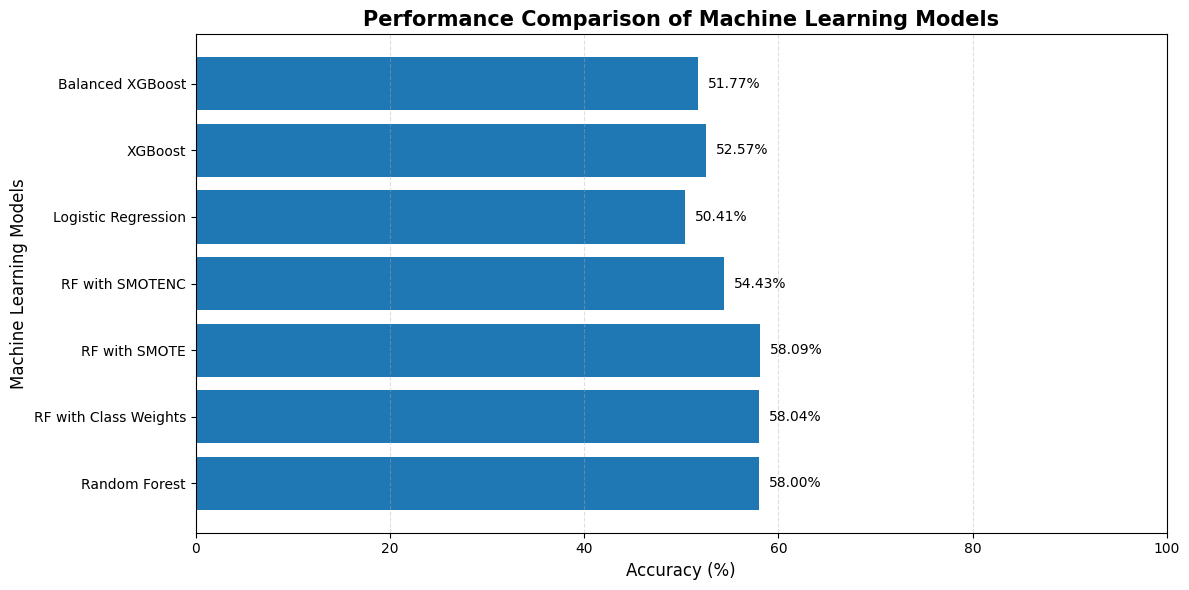

In [112]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

bars = plt.barh(
    comparison['Model'],
    comparison['Accuracy'] * 100
)

plt.title(
    'Performance Comparison of Machine Learning Models',
    fontsize=15,
    fontweight='bold'
)

plt.xlabel('Accuracy (%)', fontsize=12)
plt.ylabel('Machine Learning Models', fontsize=12)

plt.xlim(0, 100)
plt.grid(axis='x', linestyle='--', alpha=0.4)

for bar in bars:
    width = bar.get_width()
    plt.text(
        width + 1,
        bar.get_y() + bar.get_height() / 2,
        f'{width:.2f}%',
        va='center',
        fontsize=10
    )

plt.tight_layout()
plt.show()

Comparing Early Readmission Detection (Class 2 Recall)

Visualises the Class 2 recall of different models to compare their ability to identify patients readmitted within 30 days.

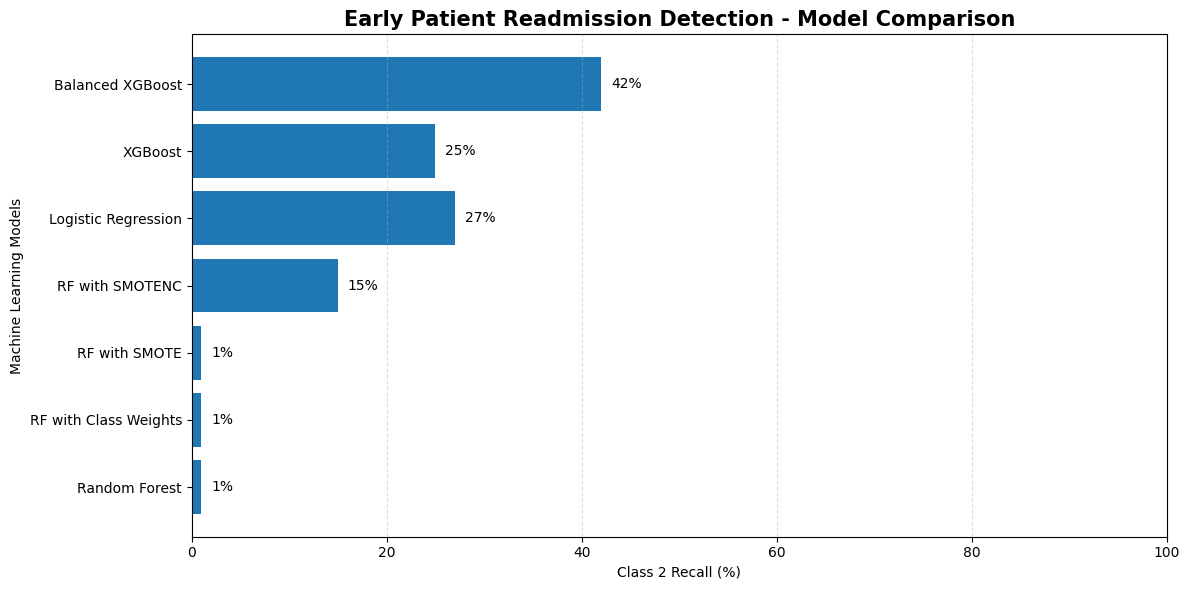

In [113]:
plt.figure(figsize=(12, 6))

bars = plt.barh(
    comparison['Model'],
    comparison['Class 2 Recall'] * 100
)

plt.title(
    'Early Patient Readmission Detection - Model Comparison',
    fontsize=15,
    fontweight='bold'
)

plt.xlabel('Class 2 Recall (%)')
plt.ylabel('Machine Learning Models')

plt.xlim(0, 100)
plt.grid(axis='x', linestyle='--', alpha=0.4)

for bar in bars:
    width = bar.get_width()
    plt.text(
        width + 1,
        bar.get_y() + bar.get_height() / 2,
        f'{width:.0f}%',
        va='center'
    )

plt.tight_layout()
plt.show()

Observations from Model Comparison

1. XGBoost achieved the highest overall accuracy of 59.48%.
2. Balanced XGBoost achieved the highest recall of 42% for early readmission (Class 2).
3. Logistic Regression achieved 27% recall for Class 2.
4. Class balancing improved the detection of early readmission cases.
5. Further improvements are required to increase model performance.

Conclusion

The experimental results show that different machine learning algorithms perform differently on the patient readmission dataset. Balanced XGBoost showed better detection of early readmission cases, while standard XGBoost achieved higher overall accuracy.

Confusion Matrix of Balanced XGBoost Model

Visualises the prediction results of the Balanced XGBoost model using patient counts and row-wise percentages to evaluate its classification performance across all three readmission categories.

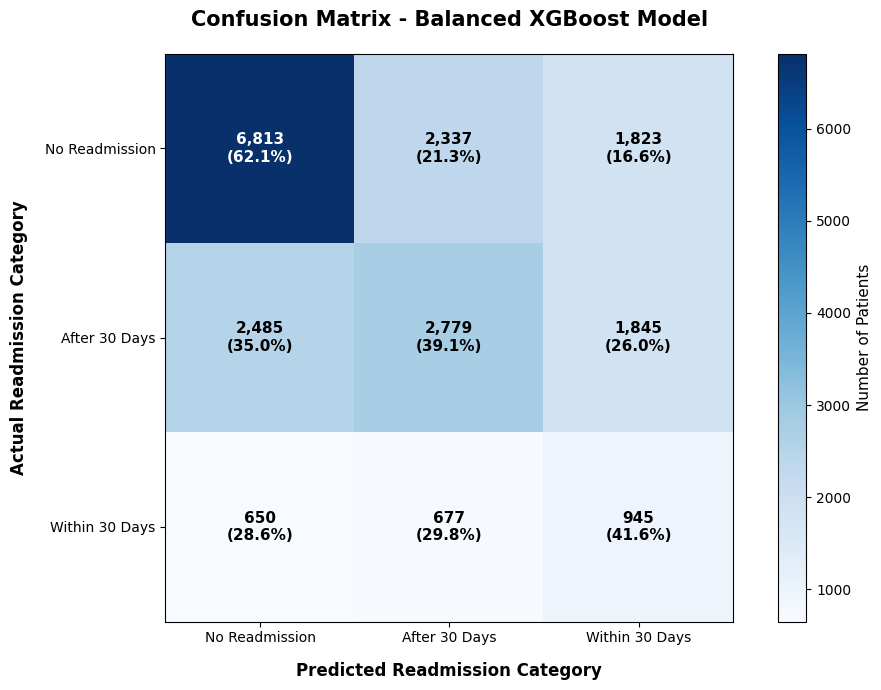

In [114]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# Confusion matrix
cm = confusion_matrix(y_test, y_pred_balanced)

# Calculate row-wise percentages
percentages = cm.astype(float) / cm.sum(axis=1)[:, np.newaxis] * 100

labels = [
    'No Readmission',
    'After 30 Days',
    'Within 30 Days'
]

# Create professional figure
fig, ax = plt.subplots(figsize=(10, 7))

im = ax.imshow(cm, cmap='Blues')

# Add colour bar
cbar = fig.colorbar(im, ax=ax)
cbar.set_label('Number of Patients', fontsize=11)

# Axis labels
ax.set_xticks(np.arange(3))
ax.set_yticks(np.arange(3))

ax.set_xticklabels(labels, fontsize=10)
ax.set_yticklabels(labels, fontsize=10)

ax.set_xlabel('Predicted Readmission Category',
              fontsize=12, fontweight='bold', labelpad=12)

ax.set_ylabel('Actual Readmission Category',
              fontsize=12, fontweight='bold', labelpad=12)

ax.set_title(
    'Confusion Matrix - Balanced XGBoost Model',
    fontsize=15,
    fontweight='bold',
    pad=20
)

# Add counts and percentages
threshold = cm.max() / 2

for i in range(3):
    for j in range(3):
        color = 'white' if cm[i, j] > threshold else 'black'

        ax.text(
            j, i,
            f'{cm[i, j]:,}\n({percentages[i, j]:.1f}%)',
            ha='center',
            va='center',
            color=color,
            fontsize=11,
            fontweight='bold'
        )

plt.tight_layout()
plt.show()

Checking Required Variables

This step verifies whether the training data, testing data, preprocessing object, and trained Balanced XGBoost model are available in the current Python environment.

In [ ]:
print("X_train:", 'X_train' in globals())
print("X_test:", 'X_test' in globals())
print("y_train:", 'y_train' in globals())
print("y_test:", 'y_test' in globals())
print("preprocessor_xgb:", 'preprocessor_xgb' in globals())
print("xgb_model_balanced:", 'xgb_model_balanced' in globals())

X_train: True
X_test: True
y_train: True
y_test: True
preprocessor_xgb: True
xgb_model_balanced: True


Saving the Trained Model

This step saves the trained Balanced XGBoost model and its preprocessor into a single `.pkl` file using Joblib. These saved objects can be loaded later without training the model again.

In [116]:
import joblib

joblib.dump(
    {
        "preprocessor": preprocessor_xgb,
        "model": xgb_model_balanced
    },
    "patient_readmission_model.pkl"
)

print("Model and preprocessor saved successfully!")

Model and preprocessor saved successfully!


 Verifying the Saved Model File

This step checks whether the trained model file exists and displays its file size to confirm successful saving.

In [117]:
import os

file_name = "patient_readmission_model.pkl"

print("File exists:", os.path.exists(file_name))

if os.path.exists(file_name):
    print("File size:", os.path.getsize(file_name), "bytes")

File exists: True
File size: 743281 bytes


Loading the Saved Model

The saved model and preprocessing object are loaded using Joblib for further testing and prediction.

In [118]:
import joblib

saved_objects = joblib.load("patient_readmission_model.pkl")

loaded_preprocessor = saved_objects["preprocessor"]
loaded_model = saved_objects["model"]

print("Preprocessor loaded successfully!")
print("Balanced XGBoost model loaded successfully!")

Preprocessor loaded successfully!
Balanced XGBoost model loaded successfully!


Generating Predictions Using the Saved Model

This step uses the loaded preprocessor to transform the test data and the saved Balanced XGBoost model to generate readmission predictions.

In [119]:
X_test_processed = loaded_preprocessor.transform(X_test)

y_pred_saved = loaded_model.predict(X_test_processed)

print("Predictions generated successfully!")
print("First 10 predictions:", y_pred_saved[:10])

Predictions generated successfully!
First 10 predictions: [0 0 2 0 1 0 2 1 0 2]


 Evaluating the Saved Model Accuracy

This step calculates the accuracy of the saved model by comparing its predictions with the actual test data labels.

In [120]:
from sklearn.metrics import accuracy_score

saved_model_accuracy = accuracy_score(y_test, y_pred_saved)

print("Saved Model Accuracy:", saved_model_accuracy)

Saved Model Accuracy: 0.5176869411417903


Verifying Saved Model Predictions

This step compares the predictions from the original trained model with those from the loaded saved model to verify that both produce identical predictions.

In [121]:
from sklearn.metrics import accuracy_score

original_predictions = xgb_model_balanced.predict(X_test_encoded)

print(
    "Original and saved predictions match:",
    (original_predictions == y_pred_saved).all()
)

Original and saved predictions match: True


Final Saved Model Evaluation

This step evaluates the saved Balanced XGBoost model using Accuracy, Precision, Recall, and F1-score for Class 2 (patients readmitted within 30 days).

In [122]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

precision, recall, f1, _ = precision_recall_fscore_support(
    y_test, y_pred_saved, labels=[2], zero_division=0
)

print("Final Saved Model Evaluation")
print("Accuracy:", accuracy_score(y_test, y_pred_saved))
print("Class 2 Precision:", precision[0])
print("Class 2 Recall:", recall[0])
print("Class 2 F1-score:", f1[0])

Final Saved Model Evaluation
Accuracy: 0.5176869411417903
Class 2 Precision: 0.20485584218512898
Class 2 Recall: 0.4159330985915493
Class 2 F1-score: 0.27450980392156865
